In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B10 – Kết Hợp Nhiều Mô Hình Để Phát Hiện Tấn Công ICS
## Voting & Stacking Ensemble – Dataset BATADAL

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.ensemble import (RandomForestClassifier, StackingClassifier,
                              VotingClassifier)
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
BASE = Path("data/BATADAL")
for _cand in [BASE, Path.cwd().parent / "B9" / "data" / "BATADAL",
              Path.cwd().parent / "B8" / "data" / "BATADAL",
              Path.cwd().parent / "B1" / "data" / "BATADAL"]:
    if (_cand / "test_dataset_1.csv").exists():
        BASE = _cand
        break

LABEL_COL = "ATT_FLAG"
TARGET_NAMES = ["Bình thường", "Tấn công"]
META_COLS = ["DATETIME"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42
TEST_SIZE = 0.3
CV_FOLDS = 5
MAX_ITER = 200000          # chặn trên số vòng lặp của libsvm (xem bài SVM)

# ==========================
# SIÊU THAM SỐ MÔ HÌNH CƠ SỞ
# ==========================
# Những giá trị này KHÔNG phải mặc định — chúng là kết quả dò siêu tham số ở
# các bài trước của công việc này. Bài ensemble tái sử dụng chúng thay vì dò
# lại từ đầu.
KNN_K = 1                  # từ bài KNN
KNN_METRIC = "manhattan"
KNN_W = "uniform"
NB_TF = "std"                # "power" = PowerTransformer, "std" = Z-score
NB_VS = 1.0                  # var_smoothing, từ bài Naive Bayes
SVM_C = 100.0                  # từ bài SVM
SVM_G = 0.01
TREE_DEPTH = 10                  # cây quyết định thêm vào để tăng đa dạng

# Trọng số cho Soft Voting có trọng số: [knn, nb, svm, tree, lr]
VOTE_WEIGHTS = [1, 1, 2, 1, 1]

# Giới hạn trục cho các biểu đồ cột
VOTE_XLIM = (0.55, 1.0)

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
BASE_COMMENT = (
    "\nNhận xét: các mô hình cơ sở CHÊNH LỆCH RẤT LỚN — từ 0,626 (Naive Bayes)\n"
    "tới 0,952 (KNN), chênh 0,326. Đây là bộ dữ liệu có khoảng cách lớn nhất\n"
    "trong ba bài ensemble, và điều đó sẽ ảnh hưởng mạnh tới voting.\n"
    "KNN dẫn đầu (0,9521) — nhưng hãy nhớ kết luận của Bài 6: con số này cao giả\n"
    "tạo do rò rỉ thời gian. Hồi quy logistic chỉ 0,808, khẳng định ranh giới\n"
    "giữa hai chế độ vận hành không tuyến tính.")
DIVERSITY_COMMENT = (
    "\nNhận xét: bất đồng trung bình 3,11% và cả năm mô hình đồng thuận ở 93,58%\n"
    "số mẫu. Nhưng trần số lý tưởng lên tới 0,998 — cao nhất trong ba bài — so\n"
    "với 0,9901 của mô hình cơ sở tốt nhất. Khoảng trống khoảng 0,008, rộng gấp\n"
    "nhiều lần hai bộ dữ liệu kia.\n"
    "Nghĩa là: ở bộ dữ liệu này, ensemble THỰC SỰ có chỗ để cải thiện. Các cặp\n"
    "bất đồng nhiều nhất đều liên quan tới Naive Bayes — mô hình yếu nhất nhưng\n"
    "cũng khác biệt nhất.")
VOTE_COMMENT = (
    "\nNhận xét: cả ba kiểu voting đều KÉM HƠN RÕ so với KNN đơn lẻ — Hard Voting\n"
    "0,920 và Soft Voting 0,923 so với 0,952. Gán trọng số 2 cho SVM cải thiện\n"
    "lên 0,943 nhưng vẫn chưa bằng.\n"
    "Đây là minh họa rõ nhất trong ba bài về giới hạn của voting: khi một mô hình\n"
    "cơ sở yếu hẳn (Naive Bayes 0,626) và một mô hình khác cũng yếu (hồi quy\n"
    "logistic 0,808), phép lấy trung bình kéo cả nhóm xuống. Hai phiếu yếu đủ\n"
    "sức lật ngược quyết định của ba phiếu mạnh.")
STACK_COMMENT = (
    "\nNhận xét: Stacking đạt 0,969 và biến thể passthrough lên 0,976 — vượt KNN\n"
    "đơn lẻ (0,952), vượt Soft Voting (0,923) và vượt cả Random Forest (0,961).\n"
    "Khoảng cách giữa Stacking (0,976) và Soft Voting (0,923) là 0,053 — lớn nhất\n"
    "trong ba bài. Lý do rất rõ: khi các mô hình cơ sở chênh lệch mạnh, khả năng\n"
    "HỌC trọng số trở nên quyết định. Voting không làm được, stacking làm được.\n"
    "Đây là bộ dữ liệu duy nhất trong ba bài mà ensemble thực sự đáng dùng.")
META_COMMENT = (
    "\nNhận xét: KNN nhận hệ số cao nhất (1,63), rồi cây quyết định (1,50), SVM\n"
    "(1,20), hồi quy logistic (0,86). Naive Bayes nhận hệ số ÂM (-0,89).\n"
    "Hệ số âm này là chi tiết hay nhất của bài: meta-learner không chỉ bỏ qua\n"
    "Naive Bayes mà dùng nó làm tín hiệu NGƯỢC. Nhớ lại Bài 7: Naive Bayes sai\n"
    "trên dữ liệu ICS vì giả định độc lập điều kiện bị vi phạm có hệ thống — các\n"
    "cặp cảm biến như lưu lượng bơm và trạng thái bơm mô tả cùng một hiện tượng.\n"
    "Sai CÓ HỆ THỐNG thì dự đoán được, và meta-learner khai thác đúng điều đó.\n"
    "Kết quả: mô hình yếu nhất lại đóng góp thông tin hữu ích, miễn là được kết\n"
    "hợp đúng cách.")
FINAL_COMMENT = (
    "\nNhận xét: Stacking (passthrough) đứng đầu với 0,9761, vượt Random Forest\n"
    "(0,9605) và mọi mô hình cơ sở. Chỉ 5 cảnh báo giả và 27 lần bỏ sót trên\n"
    "5.530 mẫu test.\n"
    "Đây là bộ dữ liệu duy nhất trong ba bài mà ensemble xứng đáng với chi phí.\n"
    "Đối chiếu: ở CV4.1 ensemble gần như vô ích vì các mô hình quá giống nhau; ở\n"
    "CV4.2 Random Forest đơn lẻ còn thắng ensemble.\n"
    "Nguyên tắc rút ra: ensemble có lợi khi (1) các mô hình cơ sở đa dạng, và\n"
    "(2) chúng chênh lệch về chất lượng — khi đó stacking học được cách phân bổ\n"
    "lòng tin. Nhưng đừng kết luận trước khi xem phần A8.")
HELDOUT_COMMENT = (
    "\n" + "═" * 70 + "\n"
    "CÂU TRẢ LỜI CHO CẢ CHUỖI NĂM THUẬT TOÁN CỦA CV4.4\n"
    + "═" * 70 + "\n"
    "                                  Test 1      Test 2 (held-out)\n"
    "  KNN (Bài 6)                      0,9521         0,3558\n"
    "  Naive Bayes (Bài 7)              0,6257         0,2865\n"
    "  SVM (Bài 8)                      0,9494         0,4534\n"
    "  Phát hiện bất thường (Bài 9)     0,6494         0,6587\n"
    "  Cây quyết định                   0,9375         0,4749\n"
    "  Soft Voting                      0,9228         0,3436\n"
    "  Stacking                         0,9690         0,4238\n"
    "  Random Forest                    0,9605         0,4579\n"
    "\n"
    "ENSEMBLE KHÔNG CỨU ĐƯỢC RÒ RỈ THỜI GIAN. Stacking đứng đầu trên Test 1\n"
    "(0,969) nhưng trên Test 2 chỉ còn 0,424 — thấp hơn cả cây quyết định đơn lẻ\n"
    "(0,475) và Random Forest (0,458).\n"
    "\n"
    "Lý do: cả năm mô hình cơ sở đều học từ cùng một tập dữ liệu bị rò rỉ thời\n"
    "gian, nên chúng cùng mắc CÙNG MỘT loại lỗi khi sang giai đoạn khác. Ensemble\n"
    "bù trừ được lỗi ĐỘC LẬP giữa các mô hình, nhưng không bù trừ được lỗi hệ\n"
    "thống dùng chung. Meta-learner cũng được huấn luyện trên chính dữ liệu bị rò\n"
    "rỉ đó, nên trọng số nó học được cũng không còn đúng ở giai đoạn mới.\n"
    "\n"
    "Và kết quả quan trọng nhất: mô hình phát hiện bất thường ở Bài 9 — thứ YẾU\n"
    "NHẤT trên Test 1 (0,649) — lại TỐT NHẤT trên Test 2 (0,659), vì nó không học\n"
    "từ nhãn tấn công của bất kỳ giai đoạn nào.\n"
    "\n"
    "Bài học tổng kết: không có thuật toán nào, kể cả ensemble phức tạp nhất, sửa\n"
    "được một thiết kế thực nghiệm sai. Với dữ liệu chuỗi thời gian, phải chia\n"
    "train/test theo thời gian — đó là việc phải làm TRƯỚC khi chọn mô hình.\n"
    + "═" * 70)

print("✅ Cấu hình xong!")
print(f"   Nhãn     → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   SEED = {SEED} | TEST_SIZE = {TEST_SIZE} | CV_FOLDS = {CV_FOLDS}")
print(f"   KNN      → k={KNN_K}, metric={KNN_METRIC}, weights={KNN_W}")
print(f"   NB       → biến đổi {NB_TF}, var_smoothing={NB_VS}")
print(f"   SVM      → kernel RBF, C={SVM_C}, gamma={SVM_G}")
print(f"   Tree     → max_depth={TREE_DEPTH}")


✅ Cấu hình xong!
   Nhãn     → ATT_FLAG (0 = Bình thường, 1 = Tấn công)
   SEED = 42 | TEST_SIZE = 0.3 | CV_FOLDS = 5
   KNN      → k=1, metric=manhattan, weights=uniform
   NB       → biến đổi std, var_smoothing=1.0
   SVM      → kernel RBF, C=100.0, gamma=0.01
   Tree     → max_depth=10


## 3. Hàm Tiện Ích & Định Nghĩa Mô Hình Cơ Sở

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]
    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)
    if keep_cols is not None:
        return X[list(keep_cols)], []
    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


# ════════════════════════════════════════════════════════════════════════════
# NĂM MÔ HÌNH CƠ SỞ — DÙNG LẠI SIÊU THAM SỐ ĐÃ TÌM Ở CÁC BÀI TRƯỚC
# ════════════════════════════════════════════════════════════════════════════
# Mỗi mô hình được bọc trong Pipeline riêng kèm bước tiền xử lý phù hợp với
# NÓ. Đây là điểm quan trọng: KNN và SVM cần chuẩn hóa Z-score, Naive Bayes
# cần biến đổi phân phối, còn cây quyết định thì không cần gì cả. Nếu dùng
# chung một phép tiền xử lý cho cả năm thì sẽ làm yếu một số mô hình.
#
# VotingClassifier và StackingClassifier nhận Pipeline làm mô hình cơ sở, nên
# cách tổ chức này hoạt động trực tiếp.
def make_bases():
    nb_steps = [("vt", VarianceThreshold())]
    nb_steps.append(("tf", PowerTransformer(standardize=True) if NB_TF == "power"
                     else StandardScaler()))
    nb_steps.append(("nb", GaussianNB(var_smoothing=NB_VS)))
    return [
        ("knn", Pipeline([("sc", StandardScaler()),
                          ("m", KNeighborsClassifier(n_neighbors=KNN_K,
                                                     metric=KNN_METRIC,
                                                     weights=KNN_W))])),
        ("nb", Pipeline(nb_steps)),
        ("svm", Pipeline([("sc", StandardScaler()),
                          ("m", SVC(kernel="rbf", C=SVM_C, gamma=SVM_G,
                                    probability=True, max_iter=MAX_ITER,
                                    random_state=SEED))])),
        ("tree", DecisionTreeClassifier(max_depth=TREE_DEPTH, random_state=SEED)),
        ("lr", Pipeline([("sc", StandardScaler()),
                         ("m", LogisticRegression(max_iter=2000,
                                                  random_state=SEED))])),
    ]


# ════════════════════════════════════════════════════════════════════════════
# META-LEARNER CHO STACKING
# ════════════════════════════════════════════════════════════════════════════
# Phải bọc LogisticRegression trong Pipeline có StandardScaler. Lý do: khi
# dùng passthrough=True, meta-learner nhận thêm TOÀN BỘ đặc trưng gốc chưa
# chuẩn hóa. Trên dữ liệu có biên độ hàng tỷ (ví dụ ImageBase của PE header),
# LogisticRegression sẽ không hội tụ và cho F1 = 0.
def make_meta():
    return Pipeline([("sc", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=2000, random_state=SEED))])


print("✅ Đã định nghĩa clean_numeric(), evaluate(), make_bases(), make_meta()")


✅ Đã định nghĩa clean_numeric(), evaluate(), make_bases(), make_meta()


---
# Xây Dựng Ensemble

> **Bài toán:** Phát hiện tấn công vào hệ thống cấp nước bằng cách kết hợp năm mô hình.
>
> **Ý tưởng:** kết hợp nhiều mô hình để bù trừ lỗi. Ở bộ dữ liệu này các mô hình cơ sở có chất lượng rất chênh lệch (F1 từ 0,63 đến 0,95), nên bài sẽ cho thấy rõ khác biệt giữa voting và stacking.
>
> **Câu hỏi cuối của cả chuỗi CV4.4:** ensemble có cứu được vấn đề rò rỉ thời gian đã thấy ở Bài 6, 7, 8 hay không? Phần A8 trả lời.

### A1. Tải Dữ Liệu & Chia Tập

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CẢM BIẾN BATADAL")
print("═" * 70)
print("Thư mục dữ liệu:", BASE)

test1 = pd.read_csv(BASE / "test_dataset_1.csv", index_col=0)
test2 = pd.read_csv(BASE / "test_dataset_2.csv", index_col=0)
test1.columns = test1.columns.str.strip()
test2.columns = test2.columns.str.strip()

X_raw, zero_var = clean_numeric(test1, LABEL_COL, META_COLS)
X_ho_raw, _ = clean_numeric(test2, LABEL_COL, META_COLS, keep_cols=X_raw.columns)
assert list(X_ho_raw.columns) == list(X_raw.columns), "Lệch bộ đặc trưng!"

y = (test1[LABEL_COL] != 0).astype(int).values
y_ho = (test2[LABEL_COL] != 0).astype(int).values

print(f"\nTest 1: {test1.shape} → {X_raw.shape} "
      f"(loại {len(zero_var)} cột phương sai = 0)")
print(f"Test 2 (held-out): {test2.shape} → {X_ho_raw.shape}")
print(f"Test 1 — {TARGET_NAMES[0]} = {int((y == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y == 1).sum()):,} ({y.mean()*100:.2f}%)")
print(f"Test 2 — {TARGET_NAMES[0]} = {int((y_ho == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y_ho == 1).sum()):,} ({y_ho.mean()*100:.2f}%)")

# ── Chia train/test ─────────────────────────────────────────────────────────
# Không chuẩn hóa ở đây: mỗi mô hình cơ sở có bước tiền xử lý riêng nằm trong
# Pipeline của nó (xem make_bases() ở phần 3). Nhờ vậy khi đưa vào
# VotingClassifier hay StackingClassifier, mỗi mô hình vẫn được tiền xử lý
# đúng cách của nó và không bị rò rỉ dữ liệu qua các fold.
X_tr, X_te, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} dương)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} dương)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CẢM BIẾN BATADAL
══════════════════════════════════════════════════════════════════════
Thư mục dữ liệu: data\BATADAL



Test 1: (18433, 45) → (18433, 37) (loại 6 cột phương sai = 0)
Test 2 (held-out): (10081, 45) → (10081, 37)
Test 1 — Bình thường = 16,465 | Tấn công = 1,968 (10.68%)
Test 2 — Bình thường = 8,453 | Tấn công = 1,628 (16.15%)

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 12,903 mẫu (1,378 dương)
   Test  : 5,530 mẫu (590 dương)


### A2. Năm Mô Hình Cơ Sở

          acc    prec     rec      f1  f1_macro     auc   fit_s
model                                                          
knn    0.9901  0.9785  0.9271  0.9521    0.9733  0.9623  0.0122
nb     0.9383  0.8879  0.4831  0.6257    0.7960  0.8786  0.0263
svm    0.9897  0.9963  0.9068  0.9494    0.9718  0.9947  4.8335
tree   0.9873  0.9906  0.8898  0.9375    0.9652  0.9632  0.2955
lr     0.9647  0.9625  0.6966  0.8083    0.8944  0.9682  0.1705

→ Mô hình cơ sở tốt nhất: knn (F1 = 0.9521)
→ Mô hình cơ sở yếu nhất: nb (F1 = 0.6257)
→ Khoảng cách giữa mô hình mạnh nhất và yếu nhất: 0.3264

Nhận xét: các mô hình cơ sở CHÊNH LỆCH RẤT LỚN — từ 0,626 (Naive Bayes)
tới 0,952 (KNN), chênh 0,326. Đây là bộ dữ liệu có khoảng cách lớn nhất
trong ba bài ensemble, và điều đó sẽ ảnh hưởng mạnh tới voting.
KNN dẫn đầu (0,9521) — nhưng hãy nhớ kết luận của Bài 6: con số này cao giả
tạo do rò rỉ thời gian. Hồi quy logistic chỉ 0,808, khẳng định ranh giới
giữa hai chế độ vận hành không tuyến tính.


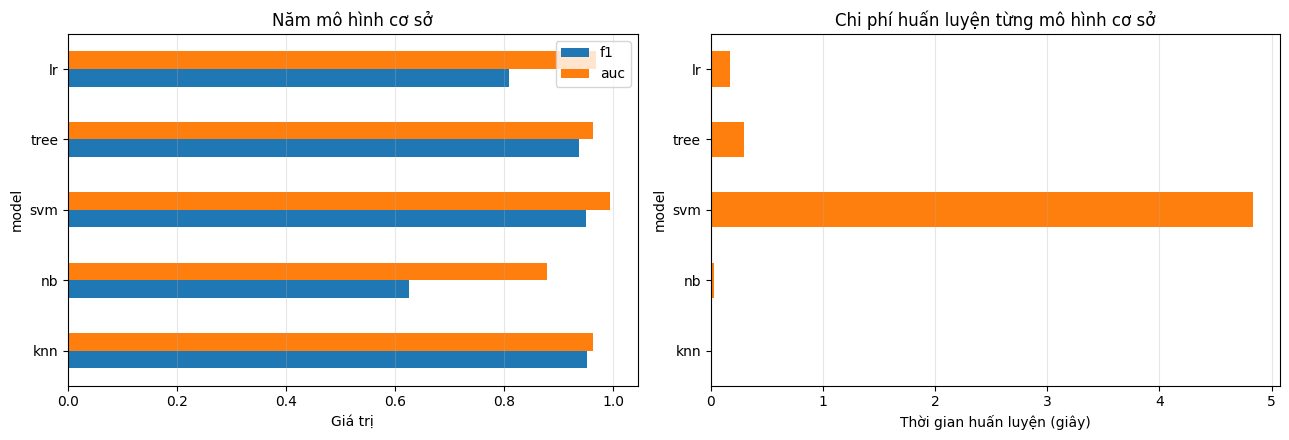

In [5]:
# Năm mô hình cơ sở, mỗi mô hình dùng đúng siêu tham số tốt nhất đã tìm được
# ở các bài trước của công việc này. Ba trong năm mô hình đến từ chính các bài
# đã học: KNN, Naive Bayes và SVM; thêm cây quyết định và hồi quy logistic để
# tăng tính đa dạng về bản chất thuật toán.
bases = make_bases()
rows, preds, probs = [], {}, {}
for tag, m in bases:
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    pr = m.predict_proba(X_te)[:, 1]
    preds[tag], probs[tag] = yp, pr
    r = evaluate(y_te, yp, pr, tag)
    r["fit_s"] = tf
    rows.append(r)

base_df = pd.DataFrame(rows).set_index("model").round(4)
print(base_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])

BASE_BEST = base_df["f1"].idxmax()
print(f"\n→ Mô hình cơ sở tốt nhất: {BASE_BEST} "
      f"(F1 = {base_df.loc[BASE_BEST, 'f1']:.4f})")
print(f"→ Mô hình cơ sở yếu nhất: {base_df['f1'].idxmin()} "
      f"(F1 = {base_df['f1'].min():.4f})")
print(f"→ Khoảng cách giữa mô hình mạnh nhất và yếu nhất: "
      f"{base_df['f1'].max() - base_df['f1'].min():.4f}")
print(BASE_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
base_df[["f1", "auc"]].plot.barh(ax=axes[0])
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Năm mô hình cơ sở")
axes[0].grid(axis="x", alpha=.3)
base_df["fit_s"].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_xlabel("Thời gian huấn luyện (giây)")
axes[1].set_title("Chi phí huấn luyện từng mô hình cơ sở")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Tính Đa Dạng – Điều Kiện Cần Để Ensemble Có Lợi

Tỷ lệ bất đồng giữa từng cặp mô hình (cao = đa dạng):
knn ↔ nb      0.0561
nb ↔ svm      0.0517
nb ↔ tree     0.0512
knn ↔ lr      0.0336
nb ↔ lr       0.0289
tree ↔ lr     0.0255
svm ↔ lr      0.0253
knn ↔ tree    0.0179
knn ↔ svm     0.0145
svm ↔ tree    0.0067

Bất đồng trung bình: 0.0311
Tỷ lệ mẫu mà cả 5 mô hình cùng dự đoán giống nhau: 0.9358
Trần số lý tưởng (oracle accuracy): 0.9980
   → so với mô hình cơ sở tốt nhất: 0.9901
   → khoảng trống mà ensemble có thể khai thác: +0.0079

Nhận xét: bất đồng trung bình 3,11% và cả năm mô hình đồng thuận ở 93,58%
số mẫu. Nhưng trần số lý tưởng lên tới 0,998 — cao nhất trong ba bài — so
với 0,9901 của mô hình cơ sở tốt nhất. Khoảng trống khoảng 0,008, rộng gấp
nhiều lần hai bộ dữ liệu kia.
Nghĩa là: ở bộ dữ liệu này, ensemble THỰC SỰ có chỗ để cải thiện. Các cặp
bất đồng nhiều nhất đều liên quan tới Naive Bayes — mô hình yếu nhất nhưng
cũng khác biệt nhất.


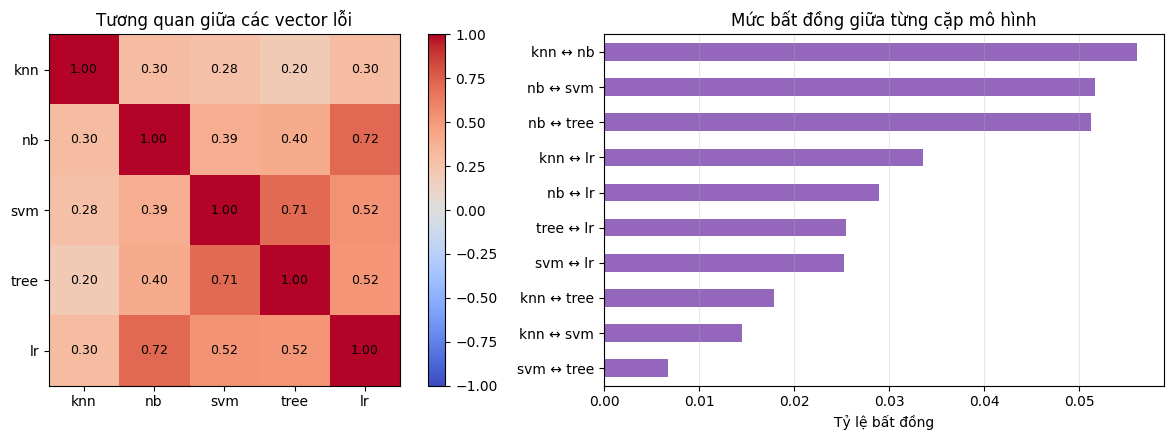

In [6]:
# Ensemble chỉ có lợi khi các mô hình cơ sở mắc lỗi KHÁC NHAU. Nếu cả năm mô
# hình cùng đúng và cùng sai ở những mẫu giống nhau thì việc kết hợp chúng
# không thêm thông tin gì.
#
# Ta đo tính đa dạng bằng ba cách:
#   1. Tỷ lệ bất đồng giữa từng cặp mô hình
#   2. Tương quan giữa các vector lỗi
#   3. "Trần số lý tưởng" (oracle): độ chính xác nếu luôn chọn được mô hình
#      đúng cho mỗi mẫu — đây là giới hạn trên mà không ensemble nào vượt được
tags = list(preds)
dis = {}
for i, a in enumerate(tags):
    for b in tags[i + 1:]:
        dis[f"{a} ↔ {b}"] = (preds[a] != preds[b]).mean()
dis_s = pd.Series(dis).sort_values(ascending=False).round(4)
print("Tỷ lệ bất đồng giữa từng cặp mô hình (cao = đa dạng):")
print(dis_s.to_string())
print(f"\nBất đồng trung bình: {dis_s.mean():.4f}")

all_agree = np.all([preds[t] == preds[tags[0]] for t in tags], axis=0)
any_right = np.any([preds[t] == y_te for t in tags], axis=0)
print(f"Tỷ lệ mẫu mà cả 5 mô hình cùng dự đoán giống nhau: {all_agree.mean():.4f}")
print(f"Trần số lý tưởng (oracle accuracy): {any_right.mean():.4f}")
print(f"   → so với mô hình cơ sở tốt nhất: "
      f"{base_df.loc[BASE_BEST, 'acc']:.4f}")
print(f"   → khoảng trống mà ensemble có thể khai thác: "
      f"{any_right.mean() - base_df.loc[BASE_BEST, 'acc']:+.4f}")
print(DIVERSITY_COMMENT)

err = pd.DataFrame({t: (preds[t] != y_te).astype(int) for t in tags})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
C = err.corr().values
im = axes[0].imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(tags)), tags)
axes[0].set_yticks(range(len(tags)), tags)
axes[0].set_title("Tương quan giữa các vector lỗi")
for i in range(len(tags)):
    for j in range(len(tags)):
        axes[0].text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=axes[0], fraction=.046)

dis_s.sort_values().plot.barh(ax=axes[1], color="tab:purple")
axes[1].set_xlabel("Tỷ lệ bất đồng")
axes[1].set_title("Mức bất đồng giữa từng cặp mô hình")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A4. Hard Voting & Soft Voting

                            acc    prec     rec      f1  f1_macro     auc  \
model                                                                       
Hard Voting              0.9841  0.9941  0.8559  0.9199    0.9555  0.9899   
Soft Voting              0.9846  0.9941  0.8610  0.9228    0.9571  0.9971   
Soft Voting có trọng số  0.9884  0.9944  0.8966  0.9430    0.9683  0.9973   

                          fit_s  
model                            
Hard Voting              7.4115  
Soft Voting              7.3912  
Soft Voting có trọng số  8.3541  

Mô hình cơ sở tốt nhất (knn) có F1 = 0.9521
   Hard Voting                F1 = 0.9199  (-0.0322 so với mô hình cơ sở tốt nhất)
   Soft Voting                F1 = 0.9228  (-0.0293 so với mô hình cơ sở tốt nhất)
   Soft Voting có trọng số    F1 = 0.9430  (-0.0091 so với mô hình cơ sở tốt nhất)

Nhận xét: cả ba kiểu voting đều KÉM HƠN RÕ so với KNN đơn lẻ — Hard Voting
0,920 và Soft Voting 0,923 so với 0,952. Gán trọng số 2 cho SVM cải thiện


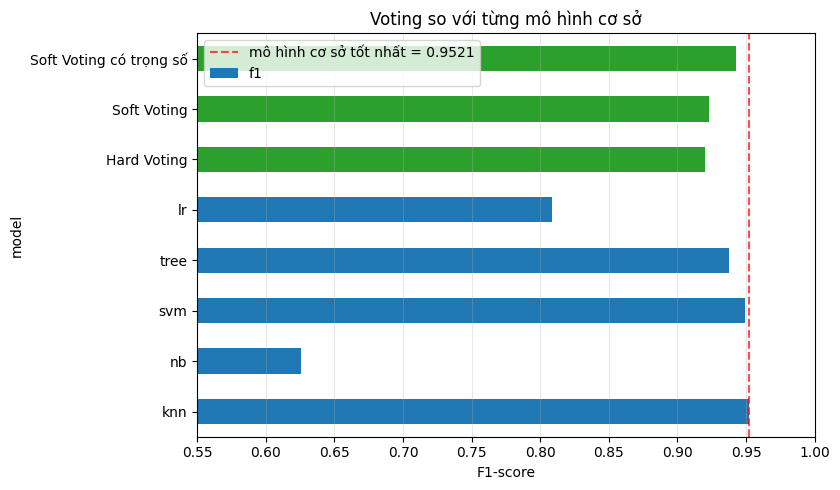

In [7]:
# Voting là cách kết hợp đơn giản nhất:
#   hard voting : mỗi mô hình bỏ một phiếu cho nhãn nó dự đoán, lấy đa số
#   soft voting : lấy trung bình xác suất của các mô hình rồi mới quyết định
#
# Soft voting thường tốt hơn vì nó dùng được mức độ tự tin: một mô hình "chắc
# 95%" có ảnh hưởng lớn hơn một mô hình "chắc 51%". Nhưng nó đòi hỏi mọi mô
# hình cơ sở phải có predict_proba — đó là lý do SVM trong bài này phải đặt
# probability=True, và vì thế huấn luyện chậm hơn nhiều.
#
# Có thể gán trọng số khác nhau cho từng mô hình. Ở đây ta thử gán trọng số 2
# cho SVM và 1 cho bốn mô hình còn lại.
rows = []
for tag, kw in [("Hard Voting", dict(voting="hard")),
                ("Soft Voting", dict(voting="soft")),
                ("Soft Voting có trọng số", dict(voting="soft",
                                                 weights=VOTE_WEIGHTS))]:
    m = VotingClassifier(estimators=make_bases(), n_jobs=-1, **kw)
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    # hard voting không có predict_proba → dùng tỷ lệ phiếu làm điểm xếp hạng
    sc = (np.mean([preds[t] for t in tags], axis=0) if kw["voting"] == "hard"
          else m.predict_proba(X_te)[:, 1])
    r = evaluate(y_te, yp, sc, tag)
    r["fit_s"] = tf
    rows.append(r)

vote_df = pd.DataFrame(rows).set_index("model").round(4)
print(vote_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])
print(f"\nMô hình cơ sở tốt nhất ({BASE_BEST}) có F1 = "
      f"{base_df.loc[BASE_BEST, 'f1']:.4f}")
for nm, v in vote_df.iterrows():
    d = v["f1"] - base_df.loc[BASE_BEST, "f1"]
    print(f"   {nm:26s} F1 = {v['f1']:.4f}  ({d:+.4f} so với mô hình cơ sở tốt nhất)")
print(VOTE_COMMENT)

ax = pd.concat([base_df[["f1"]], vote_df[["f1"]]])["f1"].plot.barh(
    figsize=(8.5, 5), color=["tab:blue"] * len(base_df) + ["tab:green"] * len(vote_df))
ax.axvline(base_df["f1"].max(), color="red", ls="--", alpha=.7,
           label=f"mô hình cơ sở tốt nhất = {base_df['f1'].max():.4f}")
ax.set_xlabel("F1-score")
ax.set_title("Voting so với từng mô hình cơ sở")
ax.set_xlim(VOTE_XLIM)
ax.legend()
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A5. Stacking Với Meta-Learner

In [8]:
# Stacking thay phép lấy trung bình bằng một mô hình HỌC CÁCH kết hợp. Quy
# trình: dùng cross-validation nội bộ để sinh dự đoán out-of-fold của từng mô
# hình cơ sở, rồi huấn luyện một meta-learner trên chính các dự đoán đó.
#
# Dùng dự đoán out-of-fold là điều bắt buộc: nếu lấy dự đoán của mô hình cơ sở
# trên dữ liệu mà nó đã được huấn luyện, các con số sẽ lạc quan giả tạo và
# meta-learner học sai.
#
# passthrough=True cho meta-learner nhận thêm cả đặc trưng GỐC, không chỉ dự
# đoán của các mô hình cơ sở — xem chú thích của make_meta() về việc vì sao
# khi đó bắt buộc phải chuẩn hóa.
rows = []
models = {}
for tag, pt in [("Stacking (meta=LR)", False),
                ("Stacking (meta=LR, passthrough)", True)]:
    m = StackingClassifier(
        estimators=make_bases(), final_estimator=make_meta(),
        cv=StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
        passthrough=pt, n_jobs=-1)
    t0 = time.perf_counter()
    m.fit(X_tr, y_tr)
    tf = time.perf_counter() - t0
    yp = m.predict(X_te)
    sc = m.predict_proba(X_te)[:, 1]
    r = evaluate(y_te, yp, sc, tag)
    r["fit_s"] = tf
    rows.append(r)
    models[tag] = m

stack_df = pd.DataFrame(rows).set_index("model").round(4)
print(stack_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "fit_s"]])
print(f"\nSo sánh nhanh:")
print(f"   Mô hình cơ sở tốt nhất : {base_df.loc[BASE_BEST, 'f1']:.4f}")
print(f"   Soft Voting            : {vote_df.loc['Soft Voting', 'f1']:.4f}")
print(f"   Stacking tốt nhất      : {stack_df['f1'].max():.4f}")
print(f"\nChi phí: Stacking mất {stack_df['fit_s'].max():.1f}s, "
      f"gấp khoảng {stack_df['fit_s'].max() / base_df['fit_s'].sum():.1f} lần "
      f"tổng thời gian huấn luyện năm mô hình cơ sở riêng lẻ "
      f"({base_df['fit_s'].sum():.1f}s) — vì cross-validation nội bộ phải huấn "
      f"luyện lại mỗi mô hình {CV_FOLDS} lần.")
print(STACK_COMMENT)

STACK_BEST = stack_df["f1"].idxmax()
stack_model = models["Stacking (meta=LR)"]


                                    acc    prec     rec      f1  f1_macro  \
model                                                                       
Stacking (meta=LR)               0.9935  0.9843  0.9542  0.9690    0.9827   
Stacking (meta=LR, passthrough)  0.9949  0.9828  0.9695  0.9761    0.9866   

                                    auc    fit_s  
model                                             
Stacking (meta=LR)               0.9972  14.4256  
Stacking (meta=LR, passthrough)  0.9979  14.8161  

So sánh nhanh:
   Mô hình cơ sở tốt nhất : 0.9521
   Soft Voting            : 0.9228
   Stacking tốt nhất      : 0.9761

Chi phí: Stacking mất 14.8s, gấp khoảng 2.8 lần tổng thời gian huấn luyện năm mô hình cơ sở riêng lẻ (5.3s) — vì cross-validation nội bộ phải huấn luyện lại mỗi mô hình 5 lần.

Nhận xét: Stacking đạt 0,969 và biến thể passthrough lên 0,976 — vượt KNN
đơn lẻ (0,952), vượt Soft Voting (0,923) và vượt cả Random Forest (0,961).
Khoảng cách giữa Stacking (0,976) và So

### A6. Meta-Learner Tin Mô Hình Nào?

Hệ số của meta-learner (Logistic Regression) ứng với từng mô hình cơ sở:
knn     1.6342
tree    1.5001
svm     1.2039
lr      0.8575
nb     -0.8849

Hệ số chặn (intercept): -4.2359

Đối chiếu với F1 của từng mô hình cơ sở:
      hệ số meta  F1 cơ sở
knn       1.6342    0.9521
lr        0.8575    0.8083
nb       -0.8849    0.6257
svm       1.2039    0.9494
tree      1.5001    0.9375

⚠ Có 1 mô hình nhận hệ số ÂM: ['nb'] — meta-learner dùng chúng làm tín hiệu ngược.

Nhận xét: KNN nhận hệ số cao nhất (1,63), rồi cây quyết định (1,50), SVM
(1,20), hồi quy logistic (0,86). Naive Bayes nhận hệ số ÂM (-0,89).
Hệ số âm này là chi tiết hay nhất của bài: meta-learner không chỉ bỏ qua
Naive Bayes mà dùng nó làm tín hiệu NGƯỢC. Nhớ lại Bài 7: Naive Bayes sai
trên dữ liệu ICS vì giả định độc lập điều kiện bị vi phạm có hệ thống — các
cặp cảm biến như lưu lượng bơm và trạng thái bơm mô tả cùng một hiện tượng.
Sai CÓ HỆ THỐNG thì dự đoán được, và meta-learner khai thác đúng điều đó.
Kết quả: mô hình

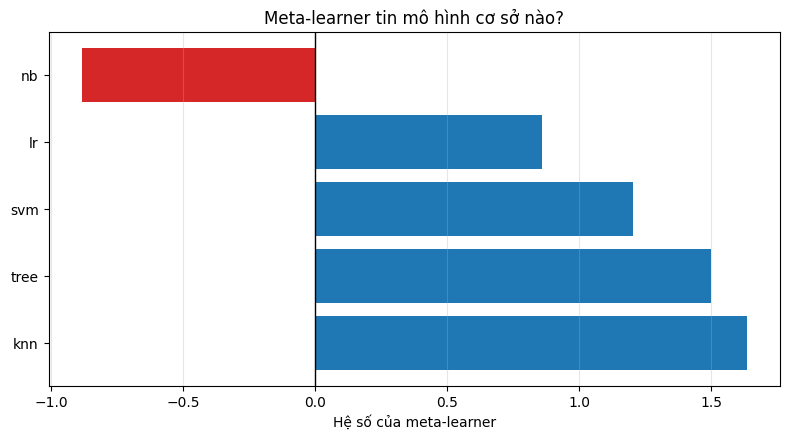

In [9]:
# Hệ số của meta-learner cho biết nó TIN mô hình nào. Đây là thứ mà voting
# không có: voting gán trọng số cố định do người dùng chọn, còn stacking HỌC
# trọng số từ dữ liệu.
#
# Hệ số ÂM đặc biệt đáng chú ý: nó nghĩa là meta-learner dùng mô hình đó như
# một tín hiệu NGƯỢC — khi mô hình ấy nói "tấn công" thì meta-learner lại
# nghiêng về "bình thường". Điều này xảy ra khi một mô hình cơ sở sai một cách
# có hệ thống ở những vùng dữ liệu nhất định.
coef = stack_model.final_estimator_["lr"].coef_.ravel()
intercept = stack_model.final_estimator_["lr"].intercept_[0]
coef_s = pd.Series(coef, index=tags).sort_values(ascending=False).round(4)

print("Hệ số của meta-learner (Logistic Regression) ứng với từng mô hình cơ sở:")
print(coef_s.to_string())
print(f"\nHệ số chặn (intercept): {intercept:.4f}")
print(f"\nĐối chiếu với F1 của từng mô hình cơ sở:")
cmp2 = pd.DataFrame({"hệ số meta": coef_s,
                     "F1 cơ sở": base_df["f1"]}).round(4)
print(cmp2.to_string())
neg = coef_s[coef_s < 0]
if len(neg):
    print(f"\n⚠ Có {len(neg)} mô hình nhận hệ số ÂM: {list(neg.index)} — "
          f"meta-learner dùng chúng làm tín hiệu ngược.")
else:
    print("\nKhông mô hình nào nhận hệ số âm.")
print(META_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["tab:red" if v < 0 else "tab:blue" for v in coef_s.values]
ax.barh(coef_s.index, coef_s.values, color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Hệ số của meta-learner")
ax.set_title("Meta-learner tin mô hình cơ sở nào?")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A7. Tổng Hợp & So Sánh Với Random Forest

                                   prec     rec      f1  f1_macro     auc    fit_s
model                                                                             
Stacking (meta=LR, passthrough)  0.9828  0.9695  0.9761    0.9866  0.9979  14.8161
Stacking (meta=LR)               0.9843  0.9542  0.9690    0.9827  0.9972  14.4256
Random Forest (200 cây)          0.9964  0.9271  0.9605    0.9780  0.9978   2.3483
Cơ sở: knn                       0.9785  0.9271  0.9521    0.9733  0.9623   0.0122
Cơ sở: svm                       0.9963  0.9068  0.9494    0.9718  0.9947   4.8335
Soft Voting có trọng số          0.9944  0.8966  0.9430    0.9683  0.9973   8.3541
Cơ sở: tree                      0.9906  0.8898  0.9375    0.9652  0.9632   0.2955
Soft Voting                      0.9941  0.8610  0.9228    0.9571  0.9971   7.3912
Hard Voting                      0.9941  0.8559  0.9199    0.9555  0.9899   7.4115
Cơ sở: lr                        0.9625  0.6966  0.8083    0.8944  0.9682   0.1705
Cơ s


Confusion matrix của Stacking: TN=4931 FP=9 FN=27 TP=563

              precision    recall  f1-score   support

 Bình thường     0.9946    0.9982    0.9964      4940
    Tấn công     0.9843    0.9542    0.9690       590

    accuracy                         0.9935      5530
   macro avg     0.9894    0.9762    0.9827      5530
weighted avg     0.9935    0.9935    0.9934      5530


Nhận xét: Stacking (passthrough) đứng đầu với 0,9761, vượt Random Forest
(0,9605) và mọi mô hình cơ sở. Chỉ 5 cảnh báo giả và 27 lần bỏ sót trên
5.530 mẫu test.
Đây là bộ dữ liệu duy nhất trong ba bài mà ensemble xứng đáng với chi phí.
Đối chiếu: ở CV4.1 ensemble gần như vô ích vì các mô hình quá giống nhau; ở
CV4.2 Random Forest đơn lẻ còn thắng ensemble.
Nguyên tắc rút ra: ensemble có lợi khi (1) các mô hình cơ sở đa dạng, và
(2) chúng chênh lệch về chất lượng — khi đó stacking học được cách phân bổ
lòng tin. Nhưng đừng kết luận trước khi xem phần A8.


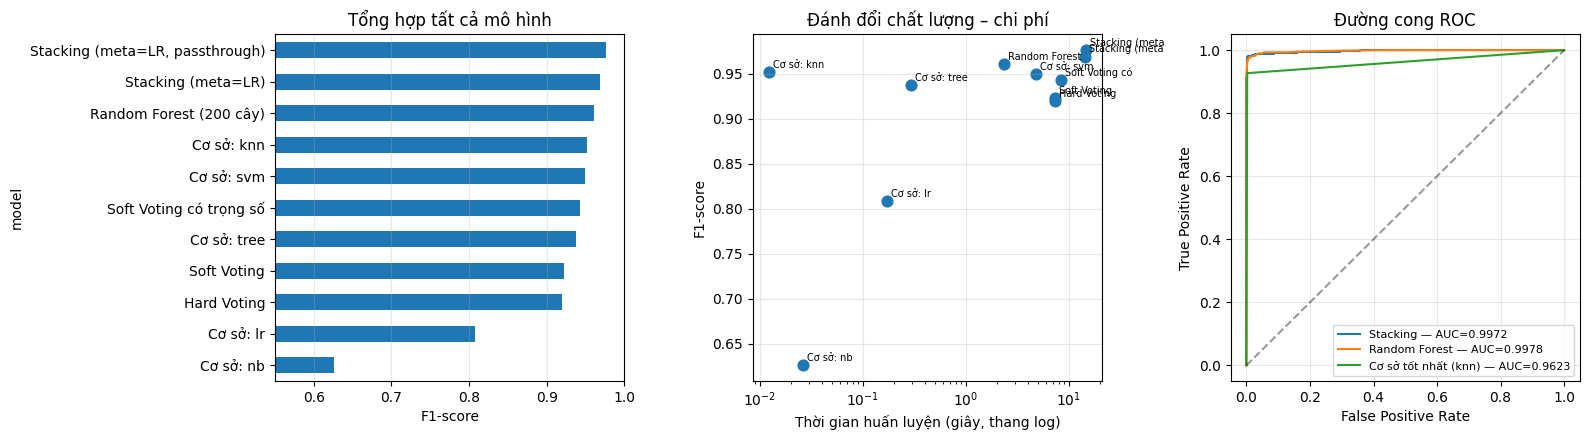

In [10]:
# Tổng hợp tất cả: năm mô hình cơ sở, ba kiểu voting, hai kiểu stacking, và
# Random Forest làm mốc so sánh. Random Forest bản thân cũng là một ensemble
# (bagging 200 cây) nên đây là phép so sánh công bằng giữa hai triết lý:
# kết hợp nhiều thuật toán KHÁC NHAU so với kết hợp nhiều bản sao của CÙNG
# một thuật toán.
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr, y_tr)
rf_t = time.perf_counter() - t0
rf_sc = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_sc, "Random Forest (200 cây)")
rf_res["fit_s"] = rf_t

all_df = pd.concat([
    base_df.rename(index=lambda s: "Cơ sở: " + s),
    vote_df, stack_df,
    pd.DataFrame([rf_res]).set_index("model"),
]).round(4)
print(all_df[["prec", "rec", "f1", "f1_macro", "auc", "fit_s"]].sort_values(
    "f1", ascending=False).to_string())

WINNER = all_df["f1"].idxmax()
print(f"\n→ Mô hình tốt nhất theo F1: {WINNER} ({all_df.loc[WINNER, 'f1']:.4f})")
print(f"→ Random Forest đứng thứ "
      f"{int((all_df['f1'] > rf_res['f1']).sum()) + 1}/{len(all_df)}")

yp_st = stack_model.predict(X_te)
cm = confusion_matrix(y_te, yp_st)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix của Stacking: TN={tn} FP={fp} FN={fn} TP={tp}")
print("\n" + classification_report(y_te, yp_st, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
all_df["f1"].sort_values().plot.barh(ax=axes[0])
axes[0].set_xlabel("F1-score")
axes[0].set_title("Tổng hợp tất cả mô hình")
axes[0].set_xlim(VOTE_XLIM)
axes[0].grid(axis="x", alpha=.3)

axes[1].scatter(all_df["fit_s"], all_df["f1"], s=60)
for nm, v in all_df.iterrows():
    axes[1].annotate(nm[:14], (v["fit_s"], v["f1"]), fontsize=7,
                     xytext=(3, 3), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Thời gian huấn luyện (giây, thang log)")
axes[1].set_ylabel("F1-score")
axes[1].set_title("Đánh đổi chất lượng – chi phí")
axes[1].grid(alpha=.3)

for nm, sc in [("Stacking", stack_model.predict_proba(X_te)[:, 1]),
               ("Random Forest", rf_sc),
               (f"Cơ sở tốt nhất ({BASE_BEST})", probs[BASE_BEST])]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Ensemble Có Cứu Được Rò Rỉ Thời Gian?

Tập held-out: (10081, 37)



                           prec     rec      f1  f1_macro     auc
model                                                            
Cơ sở: tree              0.9752  0.3139  0.4749    0.7061  0.5920
Random Forest (200 cây)  0.9760  0.2991  0.4579    0.6970  0.8762
Cơ sở: svm               0.9546  0.2973  0.4534    0.6943  0.7323
Stacking (meta=LR)       0.8950  0.2776  0.4238    0.6778  0.7461
Cơ sở: knn               0.7295  0.2353  0.3558    0.6394  0.6092
Soft Voting              0.9687  0.2088  0.3436    0.6361  0.7861
Cơ sở: nb                0.9418  0.1689  0.2865    0.6057  0.6355
Cơ sở: lr                0.9158  0.1603  0.2729    0.5983  0.6149

→ Tốt nhất trên Test 1 : 0.9761 (Stacking (meta=LR, passthrough))
→ Tốt nhất trên Test 2 : 0.4749 (Cơ sở: tree)
→ Stacking: 0.9690 → 0.4238



Confusion matrix Stacking trên Test 2: TN=8400 FP=53 FN=1176 TP=452

══════════════════════════════════════════════════════════════════════
CÂU TRẢ LỜI CHO CẢ CHUỖI NĂM THUẬT TOÁN CỦA CV4.4
══════════════════════════════════════════════════════════════════════
                                  Test 1      Test 2 (held-out)
  KNN (Bài 6)                      0,9521         0,3558
  Naive Bayes (Bài 7)              0,6257         0,2865
  SVM (Bài 8)                      0,9494         0,4534
  Phát hiện bất thường (Bài 9)     0,6494         0,6587
  Cây quyết định                   0,9375         0,4749
  Soft Voting                      0,9228         0,3436
  Stacking                         0,9690         0,4238
  Random Forest                    0,9605         0,4579

ENSEMBLE KHÔNG CỨU ĐƯỢC RÒ RỈ THỜI GIAN. Stacking đứng đầu trên Test 1
(0,969) nhưng trên Test 2 chỉ còn 0,424 — thấp hơn cả cây quyết định đơn lẻ
(0,475) và Random Forest (0,458).

Lý do: cả năm mô hình cơ sở đều học

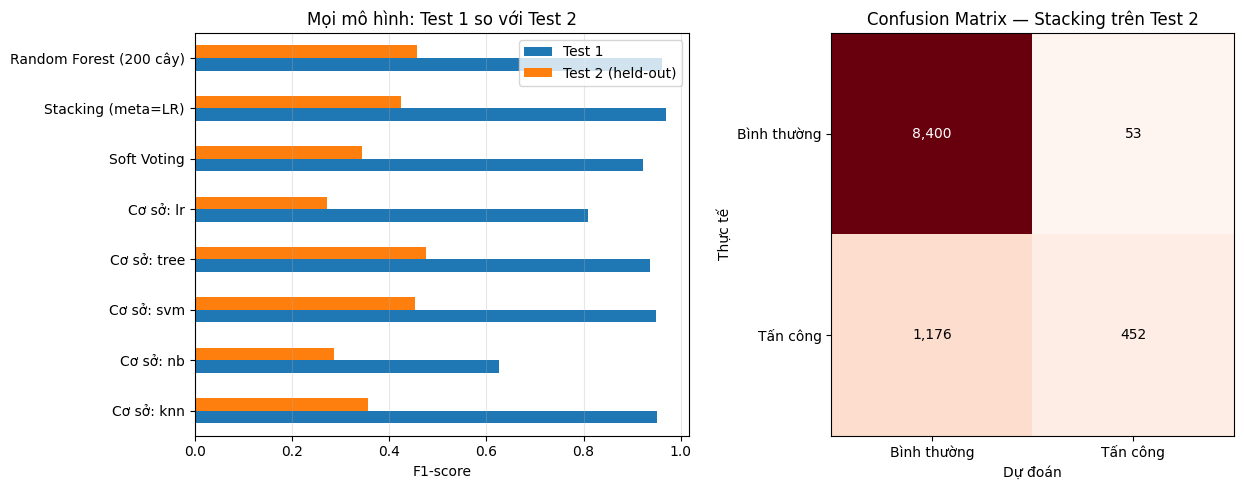

In [11]:
# Câu hỏi cuối cùng của cả chuỗi bài CV4.4: ensemble có cứu được vấn đề rò rỉ
# thời gian hay không? Ta cho tất cả các mô hình dự đoán trên test_dataset_2 —
# giai đoạn tấn công hoàn toàn khác.
Z_ho = X_ho_raw.values
print(f"Tập held-out: {Z_ho.shape}")

rows = []
for tag, m in bases:
    rows.append(evaluate(y_ho, m.predict(Z_ho), m.predict_proba(Z_ho)[:, 1],
                         "Cơ sở: " + tag))
v_soft = VotingClassifier(estimators=make_bases(), voting="soft",
                          n_jobs=-1).fit(X_tr, y_tr)
rows.append(evaluate(y_ho, v_soft.predict(Z_ho), v_soft.predict_proba(Z_ho)[:, 1],
                     "Soft Voting"))
rows.append(evaluate(y_ho, stack_model.predict(Z_ho),
                     stack_model.predict_proba(Z_ho)[:, 1], "Stacking (meta=LR)"))
rows.append(evaluate(y_ho, rf.predict(Z_ho), rf.predict_proba(Z_ho)[:, 1],
                     "Random Forest (200 cây)"))

ho_df = pd.DataFrame(rows).set_index("model").round(4)
print()
print(ho_df[["prec", "rec", "f1", "f1_macro", "auc"]].sort_values(
    "f1", ascending=False).to_string())

print(f"\n→ Tốt nhất trên Test 1 : {all_df['f1'].max():.4f} ({all_df['f1'].idxmax()})")
print(f"→ Tốt nhất trên Test 2 : {ho_df['f1'].max():.4f} ({ho_df['f1'].idxmax()})")
print(f"→ Stacking: {stack_df.loc['Stacking (meta=LR)', 'f1']:.4f} → "
      f"{ho_df.loc['Stacking (meta=LR)', 'f1']:.4f}")

cm_ho = confusion_matrix(y_ho, stack_model.predict(Z_ho))
tn2, fp2, fn2, tp2 = cm_ho.ravel()
print(f"\nConfusion matrix Stacking trên Test 2: "
      f"TN={tn2} FP={fp2} FN={fn2} TP={tp2}")
print(HELDOUT_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
comb = pd.DataFrame({
    "Test 1": [all_df.loc["Cơ sở: " + t, "f1"] for t in tags]
              + [vote_df.loc["Soft Voting", "f1"],
                 stack_df.loc["Stacking (meta=LR)", "f1"], rf_res["f1"]],
    "Test 2 (held-out)": ho_df["f1"].values,
}, index=list(ho_df.index))
comb.plot.barh(ax=axes[0])
axes[0].set_xlabel("F1-score")
axes[0].set_title("Mọi mô hình: Test 1 so với Test 2")
axes[0].grid(axis="x", alpha=.3)

axes[1].imshow(cm_ho, cmap="Reds")
for (i, j), v in np.ndenumerate(cm_ho):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm_ho.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — Stacking trên Test 2")
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Các mô hình cơ sở chênh lệch rất lớn: từ 0,626 (Naive Bayes) tới 0,952 (KNN) — khoảng cách lớn nhất trong ba bài ensemble.
2. Trần số lý tưởng lên tới 0,998 so với 0,990 của mô hình tốt nhất — khoảng trống rộng nhất, nên ensemble thực sự có chỗ cải thiện.
3. **Cả ba kiểu voting đều kém hơn rõ so với KNN đơn lẻ** (0,920–0,943 so với 0,952): hai mô hình yếu đủ sức lật ngược ba phiếu mạnh.
4. Stacking 0,969 và passthrough 0,976 — vượt KNN, vượt voting và vượt cả Random Forest (0,961). Khoảng cách Stacking – Voting là 0,053, lớn nhất trong ba bài.
5. Meta-learner gán Naive Bayes hệ số **ÂM** (-0,89), dùng chính mô hình yếu nhất làm tín hiệu ngược.
6. **Nhưng trên tập held-out, Stacking chỉ còn 0,424** — thấp hơn cây quyết định đơn lẻ (0,475) và Random Forest (0,458). Ensemble không cứu được rò rỉ thời gian.

**Câu hỏi thảo luận**

1. Vì sao voting lại kém hơn mô hình cơ sở tốt nhất ở bộ dữ liệu này, trong khi ở CV4.1 nó gần như ngang bằng? Hãy trả lời bằng khoảng chênh lệch chất lượng giữa các mô hình cơ sở.
2. Khoảng cách giữa Stacking và Soft Voting ở đây là 0,053, lớn nhất trong ba bài ensemble. Hãy giải thích mối liên hệ giữa độ chênh lệch của mô hình cơ sở và lợi thế của stacking.
3. Meta-learner gán Naive Bayes hệ số âm. Hãy nhớ lại kết luận của Bài 7 về việc giả định độc lập điều kiện bị vi phạm có hệ thống trên dữ liệu cảm biến, và giải thích vì sao điều đó khiến Naive Bayes trở thành một tín hiệu ngược hữu ích.
4. Đây là câu hỏi trọng tâm: vì sao ensemble KHÔNG cứu được rò rỉ thời gian? Hãy phân biệt giữa lỗi độc lập giữa các mô hình và lỗi hệ thống mà chúng dùng chung.
5. Mô hình phát hiện bất thường ở Bài 9 yếu nhất trên Test 1 (0,649) nhưng tốt nhất trên Test 2 (0,659). Hãy giải thích, và cho biết nếu chỉ được xem kết quả Test 1 thì bạn sẽ ra quyết định sai như thế nào.
6. Meta-learner cũng được huấn luyện trên dữ liệu bị rò rỉ thời gian. Điều đó ảnh hưởng tới các trọng số nó học được ra sao khi áp sang giai đoạn mới?
7. Sau năm bài trên cùng bộ BATADAL, hãy viết đề xuất cuối cùng cho một hệ thống phát hiện tấn công ICS thật: cách chia dữ liệu, mô hình (hoặc tổ hợp mô hình), chỉ số đánh giá, ngưỡng cảnh báo, và quy trình kiểm chứng trước khi đưa vào vận hành.
